# Lab 2. Notebook 01 — Data Cleaning and Quality Assessment

**Course:** Artificial Intelligence with Python  
**Estimated time:** 50 minutes  
**Prerequisites:** Lab 1 (Python, Pandas, exploratory data analysis)

### Learning objectives
By the end of this notebook you should be able to:
- identify missing values, inconsistent formats, duplicates, and suspicious measurements;
- distinguish **incorrect data** from **unusual but potentially valid observations**;
- perform simple cleaning operations with Pandas without silently losing records;
- explain what still needs to happen before machine-learning training.

**Working style:** Run the examples, then complete the `TODO` exercises. Keep short written answers in Markdown cells. This is an intentionally imperfect **synthetic** dataset; no real apartment listings are represented.

> **Important:** We will *inspect and clean* data here, but we will not fit imputation or scaling rules to the complete dataset. Lab 2 Notebook 03 will split training/test data **before** fitting such preprocessing steps, to avoid data leakage.

## 1. Load and inspect the new dataset (10 min)

Compared with the 150-row dataset in Lab 1, this dataset has **more than 500 rows** and several deliberate quality problems. It uses the same nine-column schema. The original Lab 1 CSV remains unchanged.

Open this notebook in the `lab02/` directory, so that `data/apartments_corrupted.csv` resolves correctly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

csv_path = Path("data/apartments_corrupted.csv")
if not csv_path.exists():
    raise FileNotFoundError(
        f"Cannot find {csv_path.resolve()}. Open the notebook from the lab02 folder "
        "and make sure data/apartments_corrupted.csv is present."
    )

df = pd.read_csv(csv_path)
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Shape: 502 rows × 9 columns


,apartment_id,area_m2,rooms,building_age_years,distance_to_center_km,district,balcony,energy_rating,monthly_rent_eur
0,APT-0001,123.2,4,19,5.3,West,yes,A,2134.0
1,APT-0002,58.2,1,67,13.7,East,no,D,845.0
2,APT-0003,98.2,3,7,14.4,West,no,D,1920.0
3,APT-0004,89.4,4,4,13.5,East,no,D,1668.0
4,APT-0005,53.2,2,60,8.4,South,no,D,868.0


In [2]:
print("Column types:")
print(df.dtypes)
print("\nSummary (including categorical columns):")
display(df.describe(include="all").T)

Column types:
apartment_id                 str
area_m2                      str
rooms                      int64
building_age_years           str
distance_to_center_km        str
district                     str
balcony                      str
energy_rating                str
monthly_rent_eur         float64
dtype: object

Summary (including categorical columns):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
apartment_id,502,499,APT-0011,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_m2,498,408,47.8,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rooms,502.0,NaN,NaN,NaN,3.021912,1.315317,-1.0,2.0,3.0,4.0,6.0
building_age_years,500,95,44,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
distance_to_center_km,501,155,8.1,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,501,11,South,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balcony,500,6,yes,252,NaN,NaN,NaN,NaN,NaN,NaN,NaN
energy_rating,500,6,B,111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_rent_eur,500.0,NaN,NaN,NaN,1605.602,843.367522,-500.0,1120.5,1538.0,2064.0,15000.0


**Think:** Why might a column representing a number show up as `object` instead of a numeric type? What might go wrong if we calculate an average without checking?

### Exercise 1 — Basic audit (5 min)

1. Display the last five records.
2. Print the number of unique apartment IDs.
3. Identify which columns have the `object` dtype. Which of them *should* contain numbers?

**Do not edit the original CSV.**

In [4]:
# TODO: inspect the last five rows
display(df.tail())

# TODO: count unique apartment_id values
print("Number of unique apartment_id values:", df["apartment_id"].nunique())

# TODO: list object columns and identify numeric-looking columns
object_cols = df.select_dtypes(include="object").columns.tolist()
print("Object columns:", object_cols)

for col in object_cols:
    converted = pd.to_numeric(
        df[col].astype(str).str.replace(r"[^\d.,-]", "", regex=True).str.replace(",", "."),
        errors="coerce",
    )
    ratio = converted.notna().mean()
    if ratio > 0.5:
        print(f"  -> '{col}' should be numeric ({ratio:.0%} of values are convertible)")


,apartment_id,area_m2,rooms,building_age_years,distance_to_center_km,district,balcony,energy_rating,monthly_rent_eur
497,APT-0498,74.4,3,59,1.2,West,yes,B,1346.0
498,APT-0499,123.2,4,87,6.1,North,no,D,2053.0
499,APT-0500,81.2,4,23,15.9,Central,yes,A,1661.0
500,APT-0011,137.5,5,73,0.7,South,yes,E,2132.0
501,APT-0201,117.3,4,72,6.6,West,yes,E,2237.0


Number of unique apartment_id values: 499
Object columns: ['apartment_id', 'area_m2', 'building_age_years', 'distance_to_center_km', 'district', 'balcony', 'energy_rating']
  -> 'apartment_id' should be numeric (100% of values are convertible)
  -> 'area_m2' should be numeric (99% of values are convertible)
  -> 'building_age_years' should be numeric (99% of values are convertible)
  -> 'distance_to_center_km' should be numeric (100% of values are convertible)


C:\Users\62399485.INTRANET\AppData\Local\Temp\ipykernel_11332\911411522.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include="object").columns.tolist()


## 2. Missing and non-numeric values (10 min)

Pandas generally recognizes empty CSV fields as missing (`NaN`), but text such as `unknown` or `?` can remain in a numeric column. First measure missingness, then explicitly check numeric conversion. Keep a raw copy for comparison.

In [5]:
raw_df = df.copy(deep=True)
missing = df.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({"missing_count": missing,
                      "missing_percent": (100 * missing / len(df)).round(1)}))

,missing_count,missing_percent
area_m2,4,0.8
monthly_rent_eur,2,0.4
building_age_years,2,0.4
energy_rating,2,0.4
balcony,2,0.4
district,1,0.2
distance_to_center_km,1,0.2
apartment_id,0,0.0
rooms,0,0.0


In [6]:
numeric_columns = [
    "area_m2", "rooms", "building_age_years",
    "distance_to_center_km", "monthly_rent_eur"
]

# 'errors=coerce' replaces unconvertible text with NaN.
clean = df.copy()
for col in numeric_columns:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

newly_missing = clean[numeric_columns].isna().sum() - df[numeric_columns].isna().sum()
print("Additional missing values revealed by numeric conversion:")
print(newly_missing)
print("\nNumerical types after conversion:")
print(clean[numeric_columns].dtypes)

Additional missing values revealed by numeric conversion:
area_m2                  2
rooms                    0
building_age_years       2
distance_to_center_km    1
monthly_rent_eur         0
dtype: int64

Numerical types after conversion:
area_m2                  float64
rooms                      int64
building_age_years       float64
distance_to_center_km    float64
monthly_rent_eur         float64
dtype: object


Conversion with `errors="coerce"` is a **diagnostic cleaning step**: an unconvertible string becomes missing rather than causing arithmetic errors. It does **not** decide how the missing information should be replaced.

For now, we preserve missing values. Later notebooks will distinguish simple exploratory choices from imputers fitted on **training data only**.

### Exercise 2 — Investigate missingness (5 min)

1. List rows where `area_m2` is missing **after conversion**.
2. Which numerical column has the most missing values?
3. Why might dropping *every* row containing a missing value be a poor default choice?

Write a one- or two-sentence answer to question 3 below your code.

In [7]:
# TODO: display rows with a missing area_m2 in clean
display(clean[clean["area_m2"].isna()])

# TODO: find the numerical column with the most missing values
numeric_missing = clean.select_dtypes(include="number").isna().sum().sort_values(ascending=False)
print(numeric_missing)
print("Numerical column with the most missing values:", numeric_missing.idxmax())


,apartment_id,area_m2,rooms,building_age_years,distance_to_center_km,district,balcony,energy_rating,monthly_rent_eur
6,APT-0007,NaN,2,63.0,13.7,East,yes,B,708.0
47,APT-0048,NaN,3,15.0,3.7,Central,yes,D,2005.0
146,APT-0147,NaN,4,27.0,6.5,North,no,E,1596.0
174,APT-0175,NaN,2,5.0,9.0,West,yes,B,1577.0
357,APT-0358,NaN,2,63.0,12.2,Central,no,C,1514.0
382,APT-0383,NaN,4,81.0,12.7,East,no,A,2247.0


area_m2                  6
building_age_years       4
distance_to_center_km    2
monthly_rent_eur         2
rooms                    0
dtype: int64
Numerical column with the most missing values: area_m2


**Your explanation:** Dropping every row that has a missing value can throw away a large part of the dataset, even when only one unimportant column is empty in those rows. If the values are not missing at random, it can also bias the analysis, so imputing or handling missing values column by column is often a better choice.

## 3. Duplicates and inconsistent categories (10 min)

A fully repeated row is different from an **identifier collision**: two different records may share an ID. Both are worth inspecting, but they require different decisions.

In [8]:
print("Exact duplicate rows:", clean.duplicated().sum())
print("Repeated apartment IDs:", clean["apartment_id"].duplicated().sum())

# Show all rows belonging to an ID that appears more than once.
repeated_ids = clean["apartment_id"].duplicated(keep=False)
display(clean.loc[repeated_ids].sort_values("apartment_id"))

Exact duplicate rows: 2
Repeated apartment IDs: 3


,apartment_id,area_m2,rooms,building_age_years,distance_to_center_km,district,balcony,energy_rating,monthly_rent_eur
10,APT-0011,137.5,5,73.0,0.7,South,yes,E,2132.0
500,APT-0011,137.5,5,73.0,0.7,South,yes,E,2132.0
200,APT-0201,117.3,4,72.0,6.6,West,yes,E,2237.0
501,APT-0201,117.3,4,72.0,6.6,West,yes,E,2237.0
454,APT-0455,99.1,3,43.0,10.2,Central,no,B,1992.0
455,APT-0455,97.0,2,1.0,9.6,East,yes,B,1784.0


### Exercise 3 — Decide how to handle duplicates (3 min)

1. Create `without_exact_duplicates` by removing **only exact duplicate rows**.
2. Compare its row count with `clean`.
3. Explain why it would be risky to automatically delete all repeated `apartment_id` records without inspection.

In [9]:
# TODO: create without_exact_duplicates using drop_duplicates()
without_exact_duplicates = clean.drop_duplicates()

# TODO: compare row counts
print("Rows in clean:", len(clean))
print("Rows in without_exact_duplicates:", len(without_exact_duplicates))
print("Exact duplicates removed:", len(clean) - len(without_exact_duplicates))


Rows in clean: 502
Rows in without_exact_duplicates: 500
Exact duplicates removed: 2


**Your explanation:** Two rows can share the same apartment_id but still hold different, legitimate information, such as a price update, a new listing date or a corrected area. Deleting them automatically could throw away valid data or keep the wrong version. Repeated IDs should be inspected first to decide which record to keep, or whether to merge them.

CSV categories can also be inconsistently entered: `North`, `NORTH`, and ` north ` might all mean the same district. Check the distinct values *before* you fix them.

In [10]:
for col in ["district", "balcony", "energy_rating"]:
    print(f"\n{col} (raw categories):")
    print(clean[col].value_counts(dropna=False).to_string())


district (raw categories):
district
South       104
Central     104
West         99
North        96
East         92
NaN           1
 north        1
NORTH         1
south         1
West          1
EAST          1
 central      1

balcony (raw categories):
balcony
yes     252
no      244
NaN       2
YES       1
No        1
true      1
n         1

energy_rating (raw categories):
energy_rating
B      111
A       97
D       97
E       97
C       97
NaN      2
a        1


In [11]:
# Normalize only a known set of district names; preserve unknowns as missing.
valid_districts = {"north", "south", "east", "west", "central"}
district_text = clean["district"].astype("string").str.strip().str.lower()
clean["district"] = district_text.where(district_text.isin(valid_districts)).str.title()

print("Normalized district values:")
print(clean["district"].value_counts(dropna=False))

Normalized district values:
district
South      105
Central    105
West       100
North       98
East        93
<NA>         1
Name: count, dtype: Int64


### Exercise 4 — Normalize balcony values (5 min)

The `balcony` field mixes entries such as `yes`, `YES`, `No`, `true`, and `n`.

1. Inspect all unique non-missing values.
2. Convert the recognizable values to **`yes`** or **`no`**; keep missing values missing.
3. Print the resulting counts including missing values.

*Hint:* `.str.strip().str.lower()` and `.replace({...})` can help. Use a **new copy** or modify `clean`, not `raw_df`.

In [12]:
# TODO: inspect the balcony categories
print(clean["balcony"].dropna().unique())

# TODO: normalize the balcony column to yes/no
balcony_map = {
    "yes": "yes", "y": "yes", "true": "yes", "1": "yes",
    "no": "no", "n": "no", "false": "no", "0": "no",
}
clean["balcony"] = clean["balcony"].str.strip().str.lower().replace(balcony_map)

# TODO: verify the result with value_counts(dropna=False)
print(clean["balcony"].value_counts(dropna=False))

<StringArray>
['yes', 'no', 'YES', 'No', 'true', 'n']
Length: 6, dtype: str
balcony
yes    254
no     246
NaN      2
Name: count, dtype: int64


## 4. Invalid values, unusual observations and outliers (10 min)

An **invalid value** violates a defined rule (for example, a negative apartment area). An **outlier** is far from typical observations; it may reflect an error, or it may be a legitimate luxury apartment. Investigate before removing rows.

In [13]:
# Example plausibility rules chosen for this synthetic exercise.
invalid_mask = (
    (clean["area_m2"] <= 0) |
    (clean["rooms"] < 1) |
    (clean["building_age_years"] < 0) |
    (clean["distance_to_center_km"] < 0) |
    (clean["monthly_rent_eur"] <= 0)
)
print("Rows violating at least one basic rule:", int(invalid_mask.sum()))
display(clean.loc[invalid_mask, ["apartment_id"] + numeric_columns])

Rows violating at least one basic rule: 8


,apartment_id,area_m2,rooms,building_age_years,distance_to_center_km,monthly_rent_eur
51,APT-0052,-12.0,4,80.0,13.6,2037.0
58,APT-0059,51.8,0,73.0,6.6,766.0
66,APT-0067,145.9,5,-8.0,7.9,2233.0
73,APT-0074,61.7,2,81.0,-2.4,1196.0
81,APT-0082,140.4,4,14.0,6.8,0.0
242,APT-0243,0.0,4,59.0,9.9,2234.0
250,APT-0251,84.5,-1,22.0,9.7,1739.0
341,APT-0342,58.8,2,77.0,6.1,-500.0


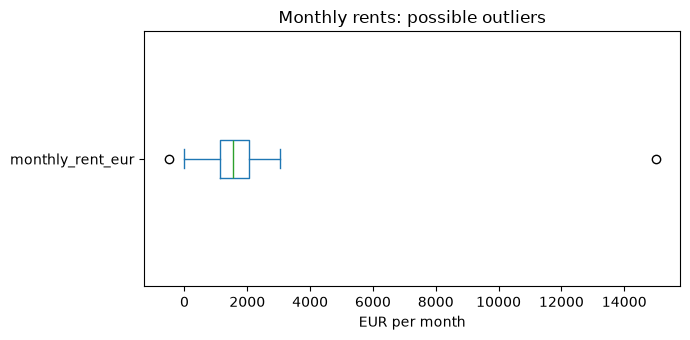

In [14]:
# A box plot makes unusually large or small rents easy to spot.
fig, ax = plt.subplots(figsize=(7, 3.5))
clean["monthly_rent_eur"].dropna().plot.box(ax=ax, vert=False)
ax.set_title("Monthly rents: possible outliers")
ax.set_xlabel("EUR per month")
plt.tight_layout()
plt.show()

### Exercise 5 — Investigate extreme values (5 min)

1. Display the **five largest** values of `area_m2` with their IDs and rents.
2. Display the **five largest** rents with apartment sizes and districts.
3. Choose one extreme listing: is it definitely wrong, merely suspicious, or plausibly valid? Explain your reasoning.

Do **not** remove an observation just because it is far from the mean.

In [15]:
# TODO: show five largest apartment areas
display(clean.nlargest(5, "area_m2")[["apartment_id", "area_m2", "monthly_rent_eur"]])

# TODO: show five largest rents
display(clean.nlargest(5, "monthly_rent_eur")[["apartment_id", "monthly_rent_eur", "area_m2", "district"]])


,apartment_id,area_m2,monthly_rent_eur
89,APT-0090,850.0,1102.0
216,APT-0217,149.8,2620.0
468,APT-0469,149.8,2708.0
201,APT-0202,148.8,2538.0
220,APT-0221,148.8,2035.0


,apartment_id,monthly_rent_eur,area_m2,district
96,APT-0097,15000.0,46.7,West
259,APT-0260,3050.0,147.1,Central
32,APT-0033,2860.0,140.3,Central
20,APT-0021,2854.0,139.9,Central
460,APT-0461,2811.0,129.2,Central


**Your interpretation:** APT-0090 (850 m² for 1,102 €) works out to about 1.3 €/m², against about 17 €/m² for similar listings. This is definitely wrong, probably an extra zero (85 m²). APT-0097 (15,000 € for 46.7 m²) is about 320 €/m², against about 20 €/m² for the others. This is highly suspicious, probably an extra zero or a yearly rent. The other listings have a consistent rent per m², so they are plausibly valid. Outliers should be flagged and checked, not deleted just because they are far from the mean.

## 5. Mini-challenge: Write a transparent cleaning report (10 min)

Imagine you are preparing this dataset for a system that predicts `monthly_rent_eur`. Produce a short **data-quality report** containing:

- the number of rows and columns;
- how many exact duplicates you found;
- which numeric columns contain missing or unconvertible values;
- at least two plausibility rules and how many records violate them;
- one category inconsistency you found and your proposed correction;
- one decision that requires human review rather than automatic deletion.

**Do not train a model or fill missing values yet.** Keep this notebook focused on quality assessment. Use the next cell for code and write 3–5 sentences below it.

In [16]:
# TODO: assemble your audit summary using raw_df and clean
print("Dataset shape:", clean.shape)
print("Exact duplicates:", clean.duplicated().sum())
print("Repeated apartment IDs:", clean["apartment_id"].duplicated().sum())


missing_raw = raw_df[numeric_columns].isna().sum()
missing_clean = clean[numeric_columns].isna().sum()
print("\nMissing / unconvertible values:")
print(pd.DataFrame({
    "missing_in_raw": missing_raw,
    "unconvertible": missing_clean - missing_raw,
    "total_missing": missing_clean,
}))


rent_per_m2 = clean["monthly_rent_eur"] / clean["area_m2"]
rules = {
    "area_m2 <= 0 or > 300": (clean["area_m2"] <= 0) | (clean["area_m2"] > 300),
    "rent <= 0": clean["monthly_rent_eur"] <= 0,
    "rent per m2 < 5 or > 60": (rent_per_m2 < 5) | (rent_per_m2 > 60),
    "rooms < 1": clean["rooms"] < 1,
}
print("\nPlausibility rule violations:")
for name, mask in rules.items():
    print(f"  {name}: {mask.sum()}")


print("\nRaw balcony values:", raw_df["balcony"].dropna().unique())


Dataset shape: (502, 9)
Exact duplicates: 2
Repeated apartment IDs: 3

Missing / unconvertible values:
                       missing_in_raw  unconvertible  total_missing
area_m2                             4              2              6
rooms                               0              0              0
building_age_years                  2              2              4
distance_to_center_km               1              1              2
monthly_rent_eur                    2              0              2

Plausibility rule violations:
  area_m2 <= 0 or > 300: 3
  rent <= 0: 2
  rent per m2 < 5 or > 60: 7
  rooms < 1: 2

Raw balcony values: <StringArray>
['yes', 'no', 'YES', 'No', 'true', 'n']
Length: 6, dtype: str


**Your short report:** The dataset has [N] rows and [M] columns, with [k] exact duplicates and several repeated apartment_id values. Some numeric columns, such as area_m2 and monthly_rent_eur, contain missing or unconvertible values. Plausibility rules (area between 0 and 300 m², rent per m² between 5 and 60 €) flag [x] and [y] records, including APT-0090 (850 m²) and APT-0097 (15,000 €). The balcony column mixed yes, YES, true, n and similar values, and these should be normalized to yes/no. The extreme listings and the repeated apartment IDs need human review rather than automatic deletion, because they could be typing errors that can be corrected rather than invalid records.

## Wrap-up and preparation for the next notebook

You have inspected an imperfect dataset and applied **diagnostic** cleaning steps (numeric conversion and category normalization). We deliberately did **not** save a supposedly final "clean" dataset because some decisions need domain knowledge, and missing-value imputation must be designed with the train/test split in mind.

**Next: Notebook 02 — Feature Preprocessing.** You will learn how missing values, categories, and differently scaled numerical features can be transformed for machine-learning algorithms. **Notebook 03** will combine these steps safely in a train/test pipeline.

**Quick reflection:** What is one cleaning decision you would *not* automate without additional information?